In [14]:
%pip install requests
# typical libraries...
import numpy as np
import matplotlib.pyplot as plt

# for importing and working with texts
import requests
import re
import string

# adjust matplotlib defaults to personal preferences
import matplotlib_inline.backend_inline
matplotlib_inline.backend_inline.set_matplotlib_formats('svg')

In [15]:
# get raw text from internet
text = requests.get('https://www.gutenberg.org/files/35/35-0.txt').text

# character strings to replace with space
strings2replace = [ '\r\n\r\nâ\x80\x9c','â\x80\x9c','â\x80\x9d','\r\n','â\x80\x94', ]

# use regular expression (re) to replace those strings with space
for str2match in strings2replace:
  text = re.compile(r'%s'%str2match).sub(' ',text)

# remove non-ASCII characters and numbers, and make lower-case
text = re.sub(r'[^\x00-\x7F]+', ' ', text)
text = re.sub('\d+','',text).lower()

<>:13: SyntaxWarning: invalid escape sequence '\d'
<>:13: SyntaxWarning: invalid escape sequence '\d'
/tmp/ipykernel_8067/3986665406.py:13: SyntaxWarning: invalid escape sequence '\d'
  text = re.sub('\d+','',text).lower()


In [16]:
# split into words that contain >1 character
words = re.split(f'[{string.punctuation}\s]+',text)
words = [item.strip() for item in words if item.strip()]
words = [item for item in words if len(item)>1]

# create the vocab
vocab = sorted(set(words))
nWords = len(words)
nLex = len(vocab)

<>:2: SyntaxWarning: invalid escape sequence '\s'
<>:2: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_8067/2590748696.py:2: SyntaxWarning: invalid escape sequence '\s'
  words = re.split(f'[{string.punctuation}\s]+',text)


In [17]:
# create the encoder/decoding mapping dictionaries
word2idx = {w:i for i,w in enumerate(vocab)}
idx2word = {i:w for i,w in enumerate(vocab)}

In [18]:
# create encoder and decoder functions
def encoder(words,encode_dict):

  # loop through the words and find their token in the vocab
  idxs = np.zeros(len(words),dtype=int)
  for i,w in enumerate(words):
    idxs[i] = encode_dict[w]
  return idxs

# and the decoder function
def decoder(idxs,decode_dict):
  return ' '.join([decode_dict[i] for i in idxs])

In [19]:
print(encoder(['the','time', 'machine'], word2idx))


[4042 4109 2416]


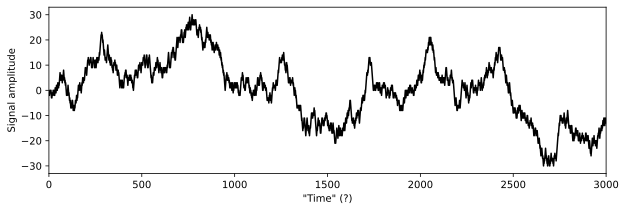

In [20]:
# A brief aside on Brownian noise
brownNoise = np.cumsum(np.random.choice([-1,1],3000))

plt.figure(figsize=(10,3))
plt.plot(brownNoise,'k')
plt.gca().set(xlim=[0,len(brownNoise)],xlabel='"Time" (?)',ylabel='Signal amplitude')
plt.show() 

In [21]:
# Brownian noise
brownNoise = np.cumsum(np.random.choice([-1,1],30))
print(brownNoise)

BrownianRandomTokens = brownNoise + np.random.choice(nLex,1)
print(BrownianRandomTokens)
print('')

# test with random token indices
print(f'Brownian random tokens: \n\t{BrownianRandomTokens}\n')
print(f'Decoded text: \n\t{decoder(BrownianRandomTokens,idx2word)}')

[ 1  2  3  4  5  4  5  4  3  2  1  2  1  2  3  2  1  0 -1 -2 -1 -2 -3 -2
 -1  0 -1 -2 -3 -2]
[4111 4112 4113 4114 4115 4114 4115 4114 4113 4112 4111 4112 4111 4112
 4113 4112 4111 4110 4109 4108 4109 4108 4107 4108 4109 4110 4109 4108
 4107 4108]

Brownian random tokens: 
	[4111 4112 4113 4114 4115 4114 4115 4114 4113 4112 4111 4112 4111 4112
 4113 4112 4111 4110 4109 4108 4109 4108 4107 4108 4109 4110 4109 4108
 4107 4108]

Decoded text: 
	times tin tint tinted tiny tinted tiny tinted tint tin times tin times tin tint tin times timepiece time till time till tiled till time timepiece time till tiled till


In [22]:
# loop through the words and count the characters per word
numChars = np.zeros(nWords)
for i,w in enumerate(words):
  numChars[i] = len(w)

# now count the number of words with those characters
charCounts = np.zeros(int(np.max(numChars)))
for i in range(len(charCounts)):
  charCounts[i] = np.sum(numChars==i)


# and plot
_,axs = plt.subplots(2,1,figsize=(10,7))
axs[0].scatter(range(nWords),numChars,marker='.',s=10,c=np.linspace(.1,.9,len(numChars)))
axs[0].set(yticks=range(1,int(np.max(numChars))),xlabel='Token index',xlim=[-15,nWords+15],
           ylabel='Number of characters',title='Character count by token index')

axs[1].bar(range(len(charCounts)),charCounts,edgecolor='k',color=[.9,.7,.9])
axs[1].set(xticks=range(1,len(charCounts)),xlim=[0,len(charCounts)],xlabel='Number of characters',
           ylabel='Token count',title='Histogram of character count frequencies')

[[<matplotlib.axis.XTick at 0x7f5aec45de50>,
 (0.0, 16.0),
 Text(0.5, 0, 'Number of characters'),
 Text(0, 0.5, 'Token count'),
 Text(0.5, 1.0, 'Histogram of character count frequencies')]

In [23]:
# the text to decode
sentence = 'The space aliens came to Earth to steal watermelons and staplers.'

# preprocess (remove punctuation, make lower-case, split into words)
words_new = re.split(rf'[{string.punctuation}\s]+',sentence.lower())

# remove empty items
words_new = [item.strip() for item in words_new if item.strip()]
words_new

['the',
 'space',
 'aliens',
 'came',
 'to',
 'earth',
 'to',
 'steal',
 'watermelons',
 'and',
 'staplers']

In [24]:
#print(encoder(words_new, word2idx)) there was an error here because the new tokens added were not present in the original vocab. So we need to add them to the vocab and re-create the encoder/decoder dictionaries.
# here i used copy to add them to the vocab and gave them the number of vocab +1 for each new token in the sentence. This is a simple way to add new tokens to the vocab, but in practice you would want to use a more sophisticated method for handling out-of-vocab tokens.

In [ ]:
# need to update the vocab
word2idx_new = word2idx.copy()
idx2word_new = idx2word.copy()

# add an entry for unknown words
word2idx_new['<|unk|>'] = len(word2idx)+1
idx2word_new[len(idx2word)+1] = '<|unk|>'